# Example 2: I have the Parquet quantities of a `goldsluice` run and want a plot

*An example for the `goldpan` / `goldsluice` note. Draft prepared with Claude Code for A. Villano, 2026-10-29.*

**The goal.** `goldsluice` has processed some pulses and written the quantities it computed as a `goldpan` Parquet dataset. Read them back with `goldpan` and draw the distribution of one quantity. (Example 1 does the same for RQ files in ROOT format.)

**The data here are made up.** `synthetic-quantities/` has a dataset definition file, `synthetic.dataset.toml`, which says which pulses were processed (the made-up traces of `synthetic-goldpan/`, 14 events, six sensors) and with which steps (all six algorithms of `goldsluice`), and `out/`, the quantities that came out of it (a 33 kB Parquet file). So the notebook runs on a fresh clone without running `goldsluice`. To use your own run, point `DEFINITION` at your definition file: the same file that `goldsluice run` used says where its output is.

Needs `goldpan` (installed by `requirements.txt`). Run with the `darkmatter_cli_env` kernel.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from goldpan.dataset import Dataset

In [2]:
# The dataset definition file; its `output` says where the quantities are.
DEFINITION = Path("synthetic-quantities") / "synthetic.dataset.toml"

ds = Dataset.open(DEFINITION)
q = ds.processed()                              # only the processed quantities, no pulses: small and fast
channels = list(q.quantities.fields[3:])        # after the event key (series, dump, event): one record per channel
names = list(q.quantities[channels[0]].fields)  # the quantities, the same for every channel

print(q)
print("channels:  ", channels)
print("quantities:", names)

Events(detector='NSDF', n_events=14, traces=[], quantities=['series', 'dump', 'event', 'Side2pC', 'Side2pF', 'Side2pE', 'Side2pB', 'Side2pA', 'Side2pD'])
channels:   ['Side2pC', 'Side2pF', 'Side2pE', 'Side2pB', 'Side2pA', 'Side2pD']
quantities: ['adc_max', 'current_max', 'max_time_s', 'baseline_mean', 'baseline_std', 'integral', 'max_deviation', 'excursion_ratio', 'rise_time_s']


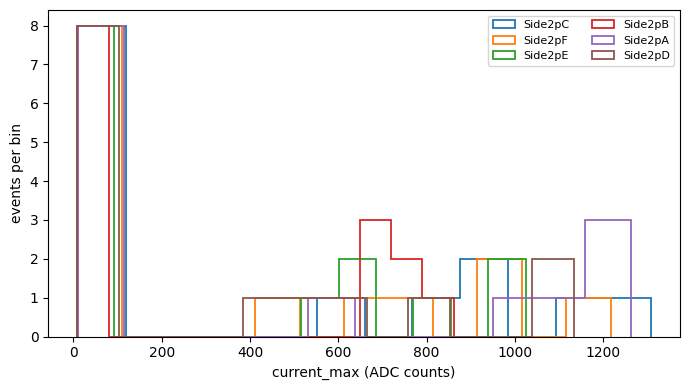

In [3]:
# One quantity for every channel: q.quantities[channel][quantity] is a column, an array with one number per event.
quantity = "current_max"                        # the largest value above the baseline (ADC counts)

fig, ax = plt.subplots(figsize=(7, 4))
for ch in channels:
    v = np.asarray(q.quantities[ch][quantity], dtype=float)
    ax.hist(v[np.isfinite(v)], bins=12, histtype="step", lw=1.3, label=ch)
ax.set_xlabel(f"{quantity} (ADC counts)")
ax.set_ylabel("events per bin")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

**What this shows.** `ds.processed()` gives the quantities as one record per event with a record per channel inside (`q.quantities["Side2pC"]["current_max"]`), and a histogram is a `numpy` histogram of one column. The quantities in the definition file's steps are all here; a new algorithm in the file would add its quantities without any change to this notebook.